In [15]:
from pathlib import Path

# Current notebook location
current_dir = Path.cwd().resolve()

print("Current Working Directory:", current_dir)

# Search for ChargingRecords.csv
search_roots = [current_dir, current_dir.parent]

DATA_PATH = None

for root in search_roots:
    matches = list(root.rglob("ChargingRecords.csv"))

    if matches:
        DATA_PATH = matches[0]
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "ChargingRecords.csv not found. "
        "Please check the project data folder."
    )

print("\nDataset Found Successfully!")
print("Dataset Path:", DATA_PATH)

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
display(df.head())

Current Working Directory: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\notebook

Dataset Found Successfully!
Dataset Path: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\ChargingRecords.csv


Dataset Shape: (72856, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [16]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print('Dataset loaded successfully.')
print(f'Rows: {df.shape[0]:,}')
print(f'Columns: {df.shape[1]}')
display(df.head())

Dataset loaded successfully.
Rows: 72,856
Columns: 13


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [17]:
print('Column names:')
print(df.columns.tolist())

print('\nDataFrame information:')
df.info()

print('\nData types by column:')
display(df.dtypes.astype(str).rename('data_type').to_frame())

Column names:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), 

,data_type
UserID,int64
ChargerID,int64
ChargerCompany,int64
Location,str
ChargerType,int64
StartDay,str
StartTime,str
EndDay,str
EndTime,str
StartDatetime,str


In [18]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UserID,72856.0,NaN,NaN,NaN,338.164667,553.970996,0.0,0.0,62.0,407.0,2501.0
ChargerID,72856.0,NaN,NaN,NaN,525.489212,569.544469,1.0,107.0,301.0,738.0,2671.0
ChargerCompany,72856.0,NaN,NaN,NaN,0.627443,0.483489,0.0,0.0,1.0,1.0,1.0
Location,72856,14,public area,14082,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChargerType,72856.0,NaN,NaN,NaN,0.20524,0.40388,0.0,0.0,0.0,0.0,1.0
StartDay,72856,366,2022-08-10,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StartTime,72856,43245,18:28:39,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndDay,72856,365,2022-07-28,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndTime,72856,46710,4:10:01,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StartDatetime,72856,65628,2022-05-16 15:10,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
missing_report = df.isna().sum().rename('missing_count').to_frame()
missing_report['missing_percent'] = (missing_report['missing_count'] / len(df) * 100).round(2)
display(missing_report.sort_values('missing_count', ascending=False))

print(f'Total duplicate rows: {df.duplicated().sum():,}')

,missing_count,missing_percent
UserID,0,0.0
ChargerID,0,0.0
ChargerCompany,0,0.0
Location,0,0.0
ChargerType,0,0.0
StartDay,0,0.0
StartTime,0,0.0
EndDay,0,0.0
EndTime,0,0.0
StartDatetime,0,0.0


Total duplicate rows: 13


In [20]:
unique_report = pd.DataFrame({
    'column': df.columns,
    'unique_values': [df[col].nunique(dropna=True) for col in df.columns],
    'data_type': [str(df[col].dtype) for col in df.columns],
})
display(unique_report.sort_values('unique_values', ascending=False).reset_index(drop=True))

for col in ['Location', 'ChargerCompany', 'ChargerType']:
    if col in df.columns:
        print(f'\nValue counts for {col}:')
        display(df[col].value_counts(dropna=False).rename_axis(col).to_frame('session_count'))

,column,unique_values,data_type
0,EndDatetime,66745,str
1,StartDatetime,65628,str
2,EndTime,46710,str
3,StartTime,43245,str
4,Demand,6046,float64
5,UserID,2337,int64
6,ChargerID,2119,int64
7,Duration,979,int64
8,StartDay,366,str
9,EndDay,365,str



Value counts for Location:


,session_count
Location,
public area,14082
apartment,14038
resort,8854
hotel,8600
company,7558
public institution,7023
public parking lot,3396
market,3005
restaurant,2222



Value counts for ChargerCompany:


,session_count
ChargerCompany,
1,45713
0,27143



Value counts for ChargerType:


,session_count
ChargerType,
0,57903
1,14953


In [21]:
date_report_rows = []
for col in ['StartDatetime', 'EndDatetime']:
    if col in df.columns:
        parsed = pd.to_datetime(df[col], errors='coerce')
        date_report_rows.append({
            'column': col,
            'invalid_datetime_count': int(parsed.isna().sum()),
            'minimum_datetime': parsed.min(),
            'maximum_datetime': parsed.max(),
        })

display(pd.DataFrame(date_report_rows))

if 'StartDatetime' in df.columns and 'EndDatetime' in df.columns:
    start_dt = pd.to_datetime(df['StartDatetime'], errors='coerce')
    end_dt = pd.to_datetime(df['EndDatetime'], errors='coerce')
    print('End time before start time:', int((end_dt < start_dt).sum()))

if 'Duration' in df.columns:
    print('Negative duration:', int((df['Duration'] < 0).sum()))
    print('Zero duration:', int((df['Duration'] == 0).sum()))
    display(df['Duration'].describe().to_frame('Duration summary'))

,column,invalid_datetime_count,minimum_datetime,maximum_datetime
0,StartDatetime,0,2021-09-30 17:14:00,2022-09-30 23:11:00
1,EndDatetime,0,2021-10-01 00:07:00,2022-09-30 23:52:00


End time before start time: 17
Negative duration: 17
Zero duration: 718


,Duration summary
count,72856.000000
mean,151.194054
std,146.430286
min,-29.000000
25%,40.000000
50%,112.000000
75%,202.000000
max,1573.000000


In [22]:
if 'Demand' not in df.columns:
    raise KeyError('The dataset does not contain the required Demand target column.')

print('Demand summary:')
display(df['Demand'].describe().to_frame('Demand'))

print(f'Demand missing values: {df["Demand"].isna().sum():,}')
print(f'Demand unique values: {df["Demand"].nunique(dropna=True):,}')

Demand summary:


,Demand
count,72856.000000
mean,17.444445
std,13.492728
min,0.010000
25%,7.530000
50%,14.100000
75%,23.200000
max,97.000000


Demand missing values: 0
Demand unique values: 6,046


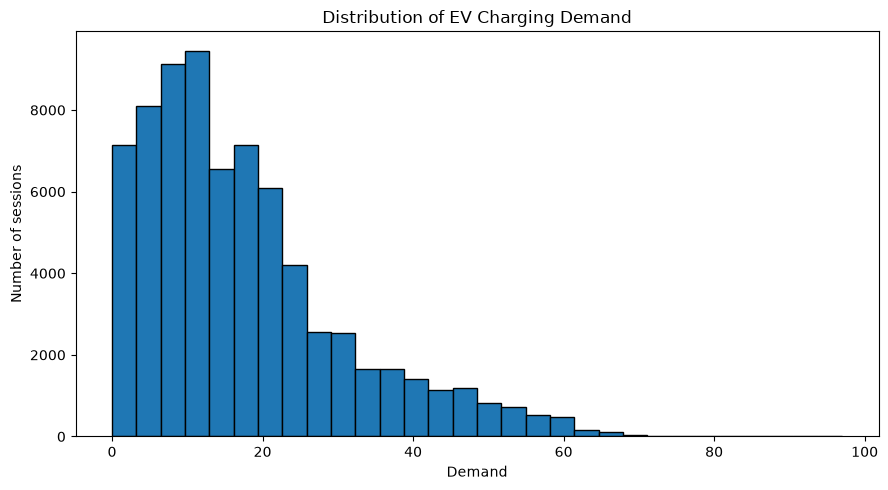

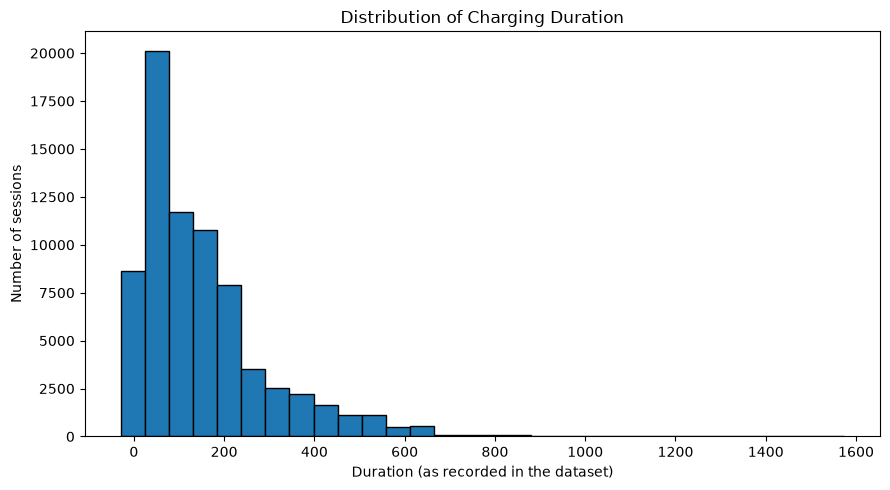

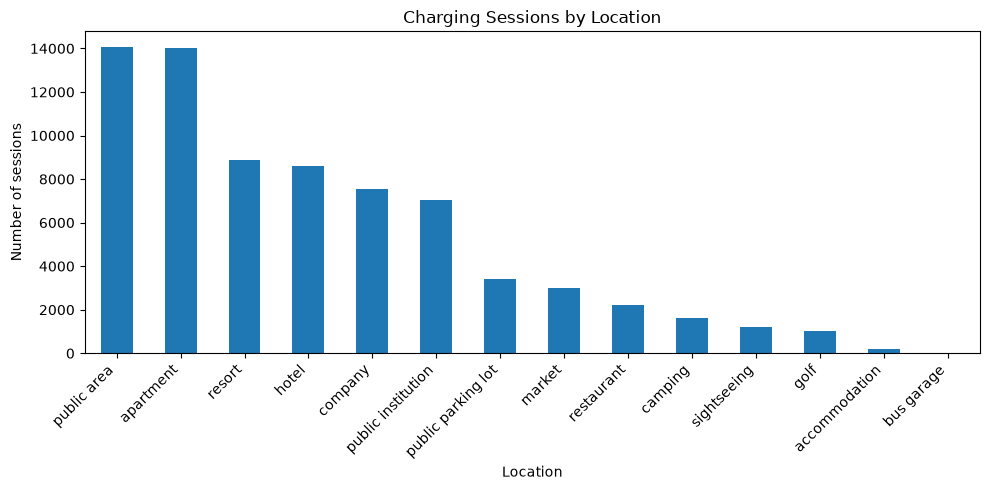

In [23]:
# Distribution of Demand
plt.figure(figsize=(9, 5))
plt.hist(df['Demand'].dropna(), bins=30, edgecolor='black')
plt.title('Distribution of EV Charging Demand')
plt.xlabel('Demand')
plt.ylabel('Number of sessions')
plt.tight_layout()
plt.show()

# Distribution of Duration
if 'Duration' in df.columns:
    plt.figure(figsize=(9, 5))
    plt.hist(df['Duration'].dropna(), bins=30, edgecolor='black')
    plt.title('Distribution of Charging Duration')
    plt.xlabel('Duration (as recorded in the dataset)')
    plt.ylabel('Number of sessions')
    plt.tight_layout()
    plt.show()

# Sessions by location
if 'Location' in df.columns:
    location_counts = df['Location'].value_counts()
    plt.figure(figsize=(10, 5))
    location_counts.plot(kind='bar')
    plt.title('Charging Sessions by Location')
    plt.xlabel('Location')
    plt.ylabel('Number of sessions')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [24]:
summary = {
    'row_count': len(df),
    'column_count': df.shape[1],
    'duplicate_rows': int(df.duplicated().sum()),
    'total_missing_cells': int(df.isna().sum().sum()),
    'unique_users': int(df['UserID'].nunique()) if 'UserID' in df.columns else None,
    'unique_chargers': int(df['ChargerID'].nunique()) if 'ChargerID' in df.columns else None,
    'unique_locations': int(df['Location'].nunique()) if 'Location' in df.columns else None,
    'demand_mean': float(df['Demand'].mean()) if 'Demand' in df.columns else None,
    'demand_median': float(df['Demand'].median()) if 'Demand' in df.columns else None,
    'negative_duration_rows': int((df['Duration'] < 0).sum()) if 'Duration' in df.columns else None,
    'zero_duration_rows': int((df['Duration'] == 0).sum()) if 'Duration' in df.columns else None,
}

display(pd.DataFrame({'value': summary}).rename_axis('metric'))

,value
metric,
row_count,72856.000000
column_count,13.000000
duplicate_rows,13.000000
total_missing_cells,0.000000
unique_users,2337.000000
unique_chargers,2119.000000
unique_locations,14.000000
demand_mean,17.444445
demand_median,14.100000
